# Model Development — Italian Day-Ahead Electricity Prices

This notebook documents the development of forecasting models for the Italian MGP market in 2024.

**Operational setting:** at 12:00 on day D−1, forecast all prices for day D. Historical price features therefore use observations from **D−2 or earlier**. Model comparison uses **July–September validation data only**; the October–December test set is reserved for `04_final_model_evaluation.ipynb`.

The original exploratory notebook included earlier experiments with previous-day prices, linear regression, Random Forest tuning and one-hot encoding. Previous-day full-hour price features are not valid for this issuance time and are **not reused as operational inputs** here.


## 1. Load and validate the original data

Download the 2024 workbook from the official GME source and place it in `data/Anno 2024_12.xlsx`. The workbook is not redistributed with this repository.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

data_path = Path("../data/Anno 2024_12.xlsx")
if not data_path.is_file():
    raise FileNotFoundError(f"Missing GME workbook: {data_path.resolve()}")

raw = pd.read_excel(data_path, sheet_name="Prezzi-Prices")
df = raw.iloc[:, :3].copy()
df.columns = ["date", "hour", "price"]
df["date"] = pd.to_datetime(df["date"].astype(str), format="%Y%m%d")
df = df.sort_values(["date", "hour"]).reset_index(drop=True)

assert len(df) == 8784
assert df[["date", "hour", "price"]].notna().all().all()
assert not df.duplicated(["date", "hour"]).any()
print("Rows:", len(df), "| Days:", df["date"].nunique())
print("Daily observation counts:", df.groupby("date").size().value_counts().sort_index().to_dict())


Rows: 8784 | Days: 366
Daily observation counts: {23: 1, 24: 364, 25: 1}


## 2. Calendar-aligned, leakage-safe features

The original investigation identified an important issue: row-based lags such as `groupby("hour").shift(2)` can become misaligned at daylight-saving transitions. The final approach joins prices by **calendar date and market hour**.

For target day D, all price observations used below come from D−2 through D−8. Rolling mean and standard deviation require all seven historical values; incomplete rows are excluded.


In [2]:
# Step 5D.3 - Calendar-aligned historical features

import pandas as pd

dayahead_safe = df[['date', 'hour', 'price']].copy()

dayahead_safe['date'] = pd.to_datetime(
    dayahead_safe['date']
)

dayahead_safe = dayahead_safe.sort_values(
    ['date', 'hour']
).reset_index(drop=True)

# Historical prices based on actual calendar dates
for lag in [2, 3, 7]:

    historical = df[['date', 'hour', 'price']].copy()

    historical['date'] = (
        pd.to_datetime(historical['date'])
        + pd.Timedelta(days=lag)
    )

    historical = historical.rename(
        columns={'price': f'price_{lag}days_ago'}
    )

    dayahead_safe = dayahead_safe.merge(
        historical,
        on=['date', 'hour'],
        how='left',
        validate='one_to_one'
    )

# Rename weekly feature
dayahead_safe = dayahead_safe.rename(
    columns={'price_7days_ago': 'price_last_week'}
)

# Calendar features
dayahead_safe['day_of_week'] = (
    dayahead_safe['date'].dt.dayofweek
)

dayahead_safe['month'] = (
    dayahead_safe['date'].dt.month
)

print("Dataset shape:", dayahead_safe.shape)

print("\nMissing values:")
print(dayahead_safe.isna().sum())

Dataset shape: (8784, 8)

Missing values:
date                 0
hour                 0
price                0
price_2days_ago     50
price_3days_ago     74
price_last_week    170
day_of_week          0
month                0
dtype: int64


In [3]:
# Step 5D.4 - Leakage-safe rolling statistics

import numpy as np

# Historical prices from t-2 to t-8
historical_features = []

for lag in range(2, 9):

    historical = df[['date', 'hour', 'price']].copy()

    historical['date'] = (
        pd.to_datetime(historical['date'])
        + pd.Timedelta(days=lag)
    )

    column_name = f'historical_price_{lag}'

    historical = historical.rename(
        columns={'price': column_name}
    )

    dayahead_safe = dayahead_safe.merge(
        historical,
        on=['date', 'hour'],
        how='left',
        validate='one_to_one'
    )

    historical_features.append(column_name)

# Require all seven historical prices
dayahead_safe['price_7day_mean'] = (
    dayahead_safe[historical_features]
    .mean(axis=1, skipna=False)
)

dayahead_safe['price_7day_std'] = (
    dayahead_safe[historical_features]
    .std(axis=1, skipna=False)
)

# Remove temporary historical columns
dayahead_safe = dayahead_safe.drop(
    columns=historical_features
)

# Check results
print("Dataset shape:", dayahead_safe.shape)

print("\nMissing values:")
print(dayahead_safe.isna().sum())

print("\nFirst valid observations:")
print(
    dayahead_safe.dropna().head(10)
)

Dataset shape: (8784, 10)

Missing values:
date                 0
hour                 0
price                0
price_2days_ago     50
price_3days_ago     74
price_last_week    170
day_of_week          0
month                0
price_7day_mean    200
price_7day_std     200
dtype: int64

First valid observations:
          date  hour      price  price_2days_ago  price_3days_ago  \
192 2024-01-09     1   87.53150            96.85            97.50   
193 2024-01-09     2   86.18151            96.58            97.67   
194 2024-01-09     3   85.00494            93.80            93.00   
195 2024-01-09     4   84.08453            93.80            93.00   
196 2024-01-09     5   84.97701            85.93            89.70   
197 2024-01-09     6   89.34054            84.30            89.47   
198 2024-01-09     7  106.76125            85.00            91.96   
199 2024-01-09     8  117.98000           102.27            96.75   
200 2024-01-09     9  131.37280           100.55            94.66 

## 3. Chronological training and validation

Train: January–June; validation: July–September. October–December observations are set aside and **not evaluated in this notebook**.

In [4]:

# Step 5D.5 - Prepare leakage-safe datasets

# Remove observations without complete historical features
dayahead_safe_clean = dayahead_safe.dropna(
    subset=[
        'price_2days_ago',
        'price_3days_ago',
        'price_last_week',
        'price_7day_mean',
        'price_7day_std'
    ]
).copy()

# Chronological split
train_safe = dayahead_safe_clean[
    dayahead_safe_clean['date'] < '2024-07-01'
].copy()

val_safe = dayahead_safe_clean[
    (dayahead_safe_clean['date'] >= '2024-07-01') &
    (dayahead_safe_clean['date'] < '2024-10-01')
].copy()

test_safe = dayahead_safe_clean[
    dayahead_safe_clean['date'] >= '2024-10-01'
].copy()

# Features
features_safe = [
    'hour',
    'day_of_week',
    'month',
    'price_2days_ago',
    'price_3days_ago',
    'price_last_week',
    'price_7day_mean',
    'price_7day_std'
]

X_train_safe = train_safe[features_safe]
y_train_safe = train_safe['price']

X_val_safe = val_safe[features_safe]
y_val_safe = val_safe['price']

X_test_safe = test_safe[features_safe]
y_test_safe = test_safe['price']

print("Training:", X_train_safe.shape)
print("Validation:", X_val_safe.shape)
print("Test:", X_test_safe.shape)

print("\nMissing values:")
print(X_train_safe.isna().sum())
print(X_val_safe.isna().sum())
print(X_test_safe.isna().sum())


Training: (4168, 8)
Validation: (2208, 8)
Test: (2208, 8)

Missing values:
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64
hour               0
day_of_week        0
month              0
price_2days_ago    0
price_3days_ago    0
price_last_week    0
price_7day_mean    0
price_7day_std     0
dtype: int64


In [ ]:
assert len(train_safe) == 4168
assert len(val_safe) == 2208
assert len(test_safe) == 2208
assert train_safe["date"].max() < val_safe["date"].min()
assert val_safe["date"].max() < test_safe["date"].min()
assert not X_train_safe.isna().any().any()
assert not X_val_safe.isna().any().any()
print("Chronological split and missing-feature checks passed.")


## 4. Compare models on validation only

We compare a day-ahead-safe historical baseline, a linear regression and two Random Forest feature sets. The linear model serves as an interpretable reference; the Random Forest configurations use the parameters retained in the original experiments (`n_estimators=200`, `max_depth=10`, `min_samples_leaf=5`, `random_state=42`).

This is a **reconstruction of the model-development comparison** on a common leakage-safe dataset, not a claim that the original earlier experiments used the same inputs. We do not tune parameters using the final test set.


In [5]:
def metrics(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }

rf_params = dict(n_estimators=200, max_depth=10,
                 min_samples_leaf=5, random_state=42, n_jobs=-1)

simple_features = [
    "hour", "day_of_week", "month",
    "price_2days_ago", "price_last_week",
]

results = []
baseline_predictions = val_safe["price_2days_ago"]
results.append({"Model": "D-2 historical baseline", **metrics(y_val_safe, baseline_predictions)})

linear = LinearRegression()
linear.fit(X_train_safe, y_train_safe)
linear_predictions = linear.predict(X_val_safe)
results.append({"Model": "Linear regression (safe features)",
                **metrics(y_val_safe, linear_predictions)})

rf_simple = RandomForestRegressor(**rf_params)
rf_simple.fit(train_safe[simple_features], y_train_safe)
results.append({"Model": "Random Forest (2 historical prices)",
                **metrics(y_val_safe, rf_simple.predict(val_safe[simple_features]))})

rf_safe = RandomForestRegressor(**rf_params)
rf_safe.fit(X_train_safe, y_train_safe)
rf_validation_predictions = rf_safe.predict(X_val_safe)
results.append({"Model": "Random Forest (full safe features)",
                **metrics(y_val_safe, rf_validation_predictions)})

validation_comparison = pd.DataFrame(results).sort_values("MAE")
print(validation_comparison.round(3).to_string(index=False))


                              Model    MAE   RMSE
  Linear regression (safe features) 10.664 15.834
 Random Forest (full safe features) 11.762 18.151
Random Forest (2 historical prices) 12.535 19.113
            D-2 historical baseline 12.678 19.056


## 5. Interpret and compare model features

**Random Forest:** impurity-based feature importance describes how the fitted trees use features; it does not imply causality.

**Linear regression:** standardized coefficients help compare the magnitudes of associations across predictors measured in different units. We fit the scaler on **training data only**, and refit the linear regression on standardized training features. Coefficients can be unstable when predictors are correlated.

**Common comparison:** permutation importance evaluates the increase in validation MAE after randomly shuffling each predictor, separately for both fitted models. A positive increase means the model relies on that feature for validation performance; negative values can occur. Correlated features may share importance, so individual permutation scores can understate their joint contribution. Validation results are diagnostic and should not be treated as an independent test.


Random Forest impurity-based importance:
price_7day_mean    0.551
price_last_week    0.195
day_of_week        0.066
hour               0.052
price_7day_std     0.038
price_2days_ago    0.036
price_3days_ago    0.034
month              0.026


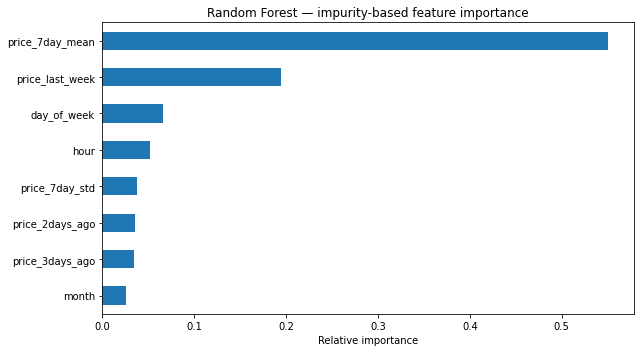


Linear regression — standardized coefficients (EUR/MWh per 1 SD):
day_of_week        -4.260
price_3days_ago    -0.890
price_7day_std     -0.155
hour                0.490
month               1.003
price_2days_ago     2.031
price_last_week     6.335
price_7day_mean    10.734


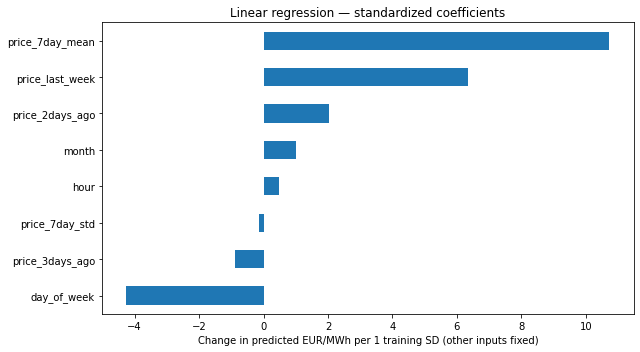


Linear regression — validation permutation importance (MAE increase, EUR/MWh):
price_7day_mean    7.028
price_last_week    1.898
day_of_week        0.668
price_2days_ago    0.507
hour               0.028
price_3days_ago    0.026
price_7day_std     0.013
month             -0.063


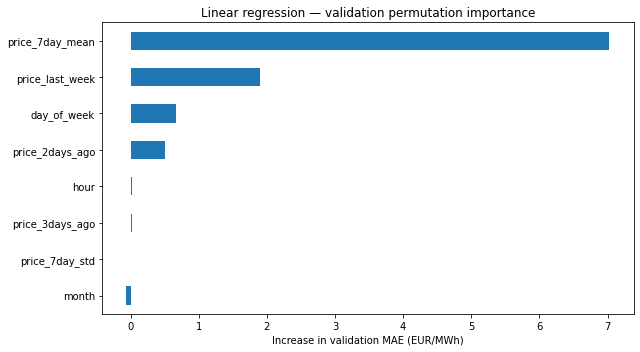


Random Forest — validation permutation importance (MAE increase, EUR/MWh):
price_7day_mean    6.295
day_of_week        1.495
price_last_week    1.355
price_2days_ago    0.338
price_3days_ago    0.296
hour               0.290
price_7day_std     0.044
month              0.000


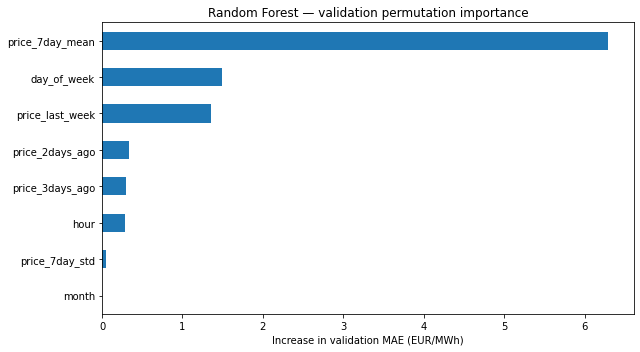

In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance

# RF impurity-based importance, learned from training data.
rf_impurity = pd.Series(rf_safe.feature_importances_, index=features_safe).sort_values()
print("Random Forest impurity-based importance:")
print(rf_impurity.sort_values(ascending=False).round(3).to_string())
rf_impurity.plot.barh(figsize=(9, 5), title="Random Forest — impurity-based feature importance")
plt.xlabel("Relative importance")
plt.tight_layout()
plt.show()

# Standardize on train only. For a linear model with an intercept, rescaling
# predictors does not change its predictions beyond floating-point tolerance.
linear_standardized = make_pipeline(StandardScaler(), LinearRegression())
linear_standardized.fit(X_train_safe, y_train_safe)
standardized_coef = pd.Series(
    linear_standardized.named_steps["linearregression"].coef_,
    index=features_safe,
).sort_values()
print("\nLinear regression — standardized coefficients (EUR/MWh per 1 SD):")
print(standardized_coef.round(3).to_string())
standardized_coef.plot.barh(figsize=(9, 5), title="Linear regression — standardized coefficients")
plt.xlabel("Change in predicted EUR/MWh per 1 training SD (other inputs fixed)")
plt.tight_layout()
plt.show()

# Same metric and same validation observations for both fitted models.
for name, model in [("Linear regression", linear_standardized),
                    ("Random Forest", rf_safe)]:
    perm = permutation_importance(
        model, X_val_safe, y_val_safe,
        scoring="neg_mean_absolute_error", n_repeats=5,
        random_state=42, n_jobs=-1,
    )
    importance = pd.Series(perm.importances_mean, index=features_safe).sort_values()
    print(f"\n{name} — validation permutation importance (MAE increase, EUR/MWh):")
    print(importance.sort_values(ascending=False).round(3).to_string())
    importance.plot.barh(figsize=(9, 5), title=f"{name} — validation permutation importance")
    plt.xlabel("Increase in validation MAE (EUR/MWh)")
    plt.tight_layout()
    plt.show()


## 6. Model selection and handoff to final evaluation

### Validation results (July–September 2024)

All models were compared on the same leakage-safe, calendar-aligned observations. The evaluation metrics below are **validation** results, not final-test results.

| Candidate | Validation MAE (EUR/MWh) | Validation RMSE (EUR/MWh) |
|---|---:|---:|
| **Linear regression (eight safe features)** | **10.664** | **15.834** |
| Random Forest (eight safe features) | 11.762 | 18.151 |
| Random Forest (two historical prices) | 12.535 | 19.113 |
| D−2 historical baseline | 12.678 | 19.056 |

**Pre-final-evaluation decision:** select the ordinary linear regression with the eight leakage-safe features as the primary model because it achieved the lowest validation MAE (and RMSE). Retain the eight-feature Random Forest and D−2 historical baseline as prespecified comparators. Do not change this selection based on October–December results.

The feature diagnostics show that both models rely heavily on the seven-day historical mean and previous-week price. Standardized linear coefficients and permutation scores describe fitted associations and predictive reliance, **not causal effects**. Correlated predictors complicate individual feature-importance interpretation.

### Reproducible handoff

`04_final_model_evaluation.ipynb` should rebuild the same eight features and chronological split, refit each prespecified model on **January–September 2024**, and report **October–December 2024** MAE/RMSE without further tuning or selection. The primary result should be the linear regression; the Random Forest and D−2 baseline provide context.

**Holdout limitation:** earlier project exploration already examined October–December test outcomes, including the original Random Forest comparison. Consequently, this period is a *previously inspected holdout*, not a completely untouched external test. This limitation must be disclosed in the final report; no additional model choices should be made after inspecting its results.

The original Random Forest test improvement over the D−2 baseline remains a historical result, but it **does not demonstrate superiority over the linear regression** in the present consistent comparison. Earlier one-hot encoding, hyperparameter tuning and ablation experiments remain in the archived source notebook and are not presented as directly comparable validation trials.

**Future work:** Milestone 6 will incorporate ex-ante demand, renewable-generation and weather forecasts, checking that each input was genuinely available at the 12:00 issuance cutoff.
